# Проект: семантический поиск товаров по текстовому запросу

**Ваша роль.** Вы специалист по Data Science. Компания развивает онлайн-каталог товаров, и сейчас руководству кажется, что классический поиск по ключевым словам плохо справляется с реальными запросами. Пользователи пишут названия с ошибками, кириллицей, используют просторечные слова, ищут товары по назначению, а не по функциональности («удобные кроссовки для бега» вместо «мужские спортивные кроссовки с амортизацией»). Команда хочет проверить, поможет ли векторный поиск улучшить качество поисковой системы.

**Задача.** Вам нужно построить MVP системы семантического поиска, сравнить его с лексической baseline-моделью на подготовленной разметке и дать бизнесу обоснованную рекомендацию о том, где новое решение помогает, где ошибается и стоит ли его вообще внедрять.

## Данные

| Файл | Что это | Когда нужен |
|---|---|---|
| wb_products_raw_sample.parquet | Исходный каталог, ~200 тысяч строк, все категории. <br> Вам нужно самостоятельно отобрать рабочее подмножество этих данных | Недели 1–2 |
| wb_products_dedup.parquet | Пул асессоров: множество товаров, по которому делалась разметка | Неделя 2, раздел 4 |
| queries_synthetic_train.parquet | Разметка релевантности, train | Недели 2–3 |
| queries_synthetic_test.parquet | Разметка релевантности, test | **один прогон** в конце недели 3 |

Файлы с разметкой содержат четыре столбца: `query_id`, `query_text`, `item_id`, `relevance`. Шкала в `relevance` от `0` до `3`, где `0` — товар нерелевантен, а `3` — максимально релевантен. Связь с каталогом: `item_id` ↔ `imt_id`.

In [52]:
import sys
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import boto3
from dotenv import load_dotenv

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

In [53]:
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)


RAW_PRODUCTS_PATH = DATA_DIR / "wb_products_raw_sample.parquet"
ASSESSED_POOL_PATH = DATA_DIR / "wb_products_dedup.parquet"
TRAIN_QUERIES_PATH = DATA_DIR / "queries_synthetic_train.parquet"
TEST_QUERIES_PATH = DATA_DIR / "queries_synthetic_test.parquet"

---

## Неделя 1 — знакомство с данными и EDA

**Цель** — понять, с какими данными работаете, чтобы принять обоснованные решения:

- выбрать категории, с которыми будете работать;
- определить, как будете очищать описания от всего лишнего;
- решить, из каких полей собирать текст товара.

**Главный критерий успеха:** любое ваше решение по данным вы можете подкрепить ссылкой на конкретные результаты анализа.

### 1. Загрузка данных

Загрузите каталог и обе разметки. Изучите их структуру: проанализируйте колонки и типы данных в них, определите, что описывает одна строка.

**Подсказка.** `imt_id` — карточка товара, `nm_id` — конкретный артикул этого товара, то есть его разновидность, отличающаяся цветом, размером или чем-то ещё. Определите, что из этого должен возвращать поиск, — от этого зависит, на каком уровне вы будете строить индекс.

In [54]:
import os

# Читаем параметры доступа
load_dotenv(override=True)

access_key = os.getenv("AWS_ACCESS_KEY_ID")
secret_key = os.getenv("AWS_SECRET_ACCESS_KEY")
endpoint = os.getenv("S3_ENDPOINT_URL")
source_bucket = os.getenv("S3_SOURCE_BUCKET")

if not all([access_key, secret_key, endpoint, source_bucket]):
    raise ValueError("В файле .env заполнены не все параметры доступа к S3.")

# Подключаемся к S3
s3 = boto3.client(
    "s3",
    endpoint_url=endpoint,
    aws_access_key_id=access_key,
    aws_secret_access_key=secret_key,
    region_name="ru-central1",
)

# Скачиваем только отсутствующие файлы
for path in [RAW_PRODUCTS_PATH, TRAIN_QUERIES_PATH, TEST_QUERIES_PATH]:
    if not path.exists():
        s3.download_file(source_bucket, path.name, str(path))

In [55]:
df_raw = pd.read_parquet(RAW_PRODUCTS_PATH)
queries_train = pd.read_parquet(TRAIN_QUERIES_PATH)
queries_test = pd.read_parquet(TEST_QUERIES_PATH)

# Ваш код: размеры, колонки, типы, первые строки
# Размеры загруженных таблиц
print("Каталог:", df_raw.shape)
print("Тренировочная разметка:", queries_train.shape)
print("Тестовая разметка:", queries_test.shape)

# Столбцы, типы данных и количество непустых значений
df_raw.info()

# Первые пять строк каталога
display(df_raw.head())

Каталог: (200000, 9)
Тренировочная разметка: (11453, 4)
Тестовая разметка: (4866, 4)
<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column           Non-Null Count   Dtype
---  ------           --------------   -----
 0   imt_id           200000 non-null  int64
 1   nm_id            200000 non-null  int64
 2   imt_name         200000 non-null  str  
 3   subj_name        200000 non-null  str  
 4   subj_root_name   200000 non-null  str  
 5   nm_colors_names  200000 non-null  str  
 6   vendor_code      200000 non-null  str  
 7   description      200000 non-null  str  
 8   brand_name       200000 non-null  str  
dtypes: int64(2), str(7)
memory usage: 169.5 MB


,imt_id,nm_id,imt_name,subj_name,subj_root_name,nm_colors_names,vendor_code,description,brand_name
0,100000,118982,Сумка,Сумки,Аксессуары,бежевый,82992/beige,,Pola
1,1000000,1206857,Шапка,Шапки,Головные уборы,белый,Лаки/белый,,Ваша Шляпка
2,1000000,1206860,Шапка,Шапки,Головные уборы,черный,Лаки/черный,,Ваша Шляпка
3,10000000,13349975,Очки TRUESPIN Fold,Солнцезащитные очки,Аксессуары,черный,20S.Y.T.35.00.564/Black/Black,,True Spin
4,10000001,13349981,Очки TRUESPIN Candor,Солнцезащитные очки,Аксессуары,черный,20S.Y.T.35.00.567/Black,,True Spin


In [56]:
queries_train.info()

# Первые пять пар «запрос — товар»
display(queries_train.head())

# Количество уникальных запросов и товаров
print("Уникальных запросов:", queries_train["query_id"].nunique())
print("Уникальных товаров:", queries_train["item_id"].nunique())

<class 'pandas.DataFrame'>
RangeIndex: 11453 entries, 0 to 11452
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   query_id    11453 non-null  str  
 1   query_text  11453 non-null  str  
 2   item_id     11453 non-null  int64
 3   relevance   11453 non-null  int64
dtypes: int64(2), str(2)
memory usage: 854.8 KB


,query_id,query_text,item_id,relevance
0,SYN_000001,жилеты на пуговицах,100211,3
1,SYN_000001,жилеты на пуговицах,100433,1
2,SYN_000001,жилеты на пуговицах,1000988,1
3,SYN_000001,жилеты на пуговицах,1016032,1
4,SYN_000001,жилеты на пуговицах,10001023,1


Уникальных запросов: 700
Уникальных товаров: 2285


**Проверьте связность данных:** все ли `item_id` из разметки есть в каталоге, нет ли пересечения `query_id` между `train` и `test`.

In [57]:
# Ваш код
# Товары из разметки, которых нет в исходном каталоге
catalog_ids = set(df_raw["imt_id"])

missing_train = set(queries_train["item_id"]) - catalog_ids
missing_test = set(queries_test["item_id"]) - catalog_ids

print("Товаров train вне каталога:", len(missing_train))
print("Товаров test вне каталога:", len(missing_test))

# Пересечение идентификаторов запросов
common_query_ids = (
    set(queries_train["query_id"]) & set(queries_test["query_id"])
)
print("Общих query_id между train и test:", len(common_query_ids))

# Пересечение текстов запросов: без учёта регистра и лишних пробелов
train_texts = (
    queries_train["query_text"]
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)
test_texts = (
    queries_test["query_text"]
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

common_query_texts = set(train_texts) & set(test_texts)
print("Общих текстов запросов между train и test:", len(common_query_texts))

Товаров train вне каталога: 0
Товаров test вне каталога: 0
Общих query_id между train и test: 0
Общих текстов запросов между train и test: 0


### 2. EDA

In [58]:
# Ваш код
# Объём каталога и уникальные идентификаторы
print("Всего строк:", len(df_raw))
print("Уникальных карточек imt_id:", df_raw["imt_id"].nunique())
print("Уникальных артикулов nm_id:", df_raw["nm_id"].nunique())

# Полные дубликаты: совпадение всех столбцов
print("Полных дубликатов:", df_raw.duplicated().sum())

# Повторные строки по идентификаторам, кроме первого вхождения
print("Повторов imt_id:", df_raw.duplicated(subset=["imt_id"]).sum())
print("Повторов nm_id:", df_raw.duplicated(subset=["nm_id"]).sum())

# Количество разных артикулов у каждой карточки
variants_per_card = df_raw.groupby("imt_id")["nm_id"].nunique()

print("Карточек с несколькими артикулами:", (variants_per_card > 1).sum())
print("Максимум артикулов у одной карточки:", variants_per_card.max())

Всего строк: 200000
Уникальных карточек imt_id: 174427
Уникальных артикулов nm_id: 199957
Полных дубликатов: 0
Повторов imt_id: 25573
Повторов nm_id: 43
Карточек с несколькими артикулами: 10632
Максимум артикулов у одной карточки: 30


In [59]:
# Все строки с повторяющимися nm_id, включая первое вхождение
duplicate_articles = df_raw[
    df_raw.duplicated(subset=["nm_id"], keep=False)
].sort_values(["nm_id", "imt_id"])

print("Артикулов с повторами:", duplicate_articles["nm_id"].nunique())
print("Строк для этих артикулов:", len(duplicate_articles))

# Поля, значения которых отличаются внутри одного nm_id
differences = (
    duplicate_articles.groupby("nm_id")
    .nunique(dropna=False)
)

print("Количество артикулов с различиями по каждому полю:")
display((differences > 1).sum())

# Все строки для первых трёх повторяющихся артикулов
example_ids = duplicate_articles["nm_id"].unique()[:3]
display(
    duplicate_articles[
        duplicate_articles["nm_id"].isin(example_ids)
    ]
)

Артикулов с повторами: 43
Строк для этих артикулов: 86
Количество артикулов с различиями по каждому полю:


imt_id              0
imt_name           13
subj_name           5
subj_root_name      0
nm_colors_names    19
vendor_code         0
description        19
brand_name          0
dtype: int64

,imt_id,nm_id,imt_name,subj_name,subj_root_name,nm_colors_names,vendor_code,description,brand_name
92826,10084538,11549279,"Гречка в варочных пакетах, 500г",Гречка,Продукты,,A37,Крупа гречневая ядрица. Первая в России гречне...,АРИВЕРА
92827,10084538,11549279,"Органическая гречка в варочных пакетах, 500 г",Гречка,Продукты,,A37,Гречка пропаренная АРИВЕРА БИО - это первая в ...,АРИВЕРА
133185,101226440,12009721,Серьги с бирюзой натуральной,Ювелирные серьги,Ювелирные украшения,"бирюзовый, золотистый, голубой",221684б0,"Комплектное кольцо арт. 12009720, комплектная ...",Елана
133186,101226440,12009721,Серьги с бирюзой натуральной,Ювелирные серьги,Ювелирные украшения,"золотистый, голубой, бирюзовый",221684б0,"Комплектное кольцо арт. 12009720, комплектная ...",Елана
11709,100108876,12465248,"Шпатель кондитерский ""Волны"", 13.5х10см",Шпатели кондитерские,Посуда и инвентарь,белый,1426890,Шпатель кондитерский Волны - Кулинарные принад...,Mellingward
11710,100108876,12465248,"Шпатель кондитерский ""Волны"", 13.5х10см",Шпатели кондитерские,Посуда и инвентарь,белый,1426890,Шпатель кондитерский Волны - Кулинарные принад...,Mellingward


In [99]:
# Проверяем полноту текстовых полей
text_columns = [
    "imt_name",
    "subj_name",
    "subj_root_name",
    "nm_colors_names",
    "vendor_code",
    "description",
    "brand_name",
]

missing_summary = []

for column in text_columns:
    values = df_raw[column]

    null_count = values.isna().sum()
    empty_count = values.fillna("").str.strip().eq("").sum() - null_count
    total_missing = null_count + empty_count

    missing_summary.append({
        "Поле": column,
        "NaN": null_count,
        "Пустые строки и пробелы": empty_count,
        "Всего пропусков": total_missing,
        "Доля пропусков, %": round(total_missing / len(df_raw) * 100, 2),
    })

missing_summary = pd.DataFrame(missing_summary)
display(missing_summary)

,Поле,NaN,Пустые строки и пробелы,Всего пропусков,"Доля пропусков, %"
0,imt_name,0,708,708,0.35
1,subj_name,0,8,8,0.00
2,subj_root_name,0,8,8,0.00
3,nm_colors_names,0,34226,34226,17.11
4,vendor_code,0,6646,6646,3.32
5,description,0,57509,57509,28.75
6,brand_name,0,201,201,0.10


In [61]:
# Проверяем отсутствие названия и описания
missing_name = df_raw["imt_name"].fillna("").str.strip().eq("")
missing_description = df_raw["description"].fillna("").str.strip().eq("")

# Признак для последующего анализа качества поиска
df_raw["has_description"] = ~missing_description

# Строки без названия и описания одновременно
missing_both = missing_name & missing_description

print("Строк без названия и описания:", missing_both.sum())
print(
    "Уникальных imt_id в этих строках:",
    df_raw.loc[missing_both, "imt_id"].nunique(),
)

display(
    df_raw.loc[
        missing_both,
        ["imt_id", "nm_id", "imt_name", "description", "subj_name"],
    ].head(10)
)

Строк без названия и описания: 163
Уникальных imt_id в этих строках: 160


,imt_id,nm_id,imt_name,description,subj_name
2390,10002112,13352568,,,Циркули
2947,10002583,13353346,,,Шорты
2948,10002584,13353347,,,Шорты
19428,10017414,13374175,,,Брюки
20237,10018304,13375293,,,Брюки
20627,10018642,13375790,,,Джинсы
23207,10020857,13378929,,,Рубашки
25255,10022720,13381544,,,Искусственные растения
25256,10022721,13381538,,,Искусственные растения
29773,10026811,13387582,,,Бриджи


In [62]:
# Есть ли хотя бы в одной строке карточки название или описание
card_has_text = (
    df_raw.assign(has_text=~missing_both)
    .groupby("imt_id")["has_text"]
    .any()
)

# Карточки, у которых все строки без названия и описания
empty_card_ids = card_has_text.index[~card_has_text]

print("Полностью пустых карточек:", len(empty_card_ids))
print(
    "Карточек с пустыми строками, но с текстом в других строках:",
    df_raw.loc[missing_both, "imt_id"].nunique() - len(empty_card_ids),
)

# Есть ли полностью пустые карточки в тренировочной разметке
print(
    "Полностью пустых карточек в train:",
    queries_train.loc[
        queries_train["item_id"].isin(empty_card_ids), "item_id"
    ].nunique(),
)

Полностью пустых карточек: 157
Карточек с пустыми строками, но с текстом в других строках: 3
Полностью пустых карточек в train: 0


In [63]:
# Распределение по корневым категориям
root_categories = (
    df_raw.groupby("subj_root_name")
    .agg(
        rows=("imt_id", "size"),
        cards=("imt_id", "nunique"),
    )
    .sort_values("cards", ascending=False)
)

# Распределение по предметным категориям внутри каждого корня
subject_categories = (
    df_raw.groupby(["subj_root_name", "subj_name"])
    .agg(
        rows=("imt_id", "size"),
        cards=("imt_id", "nunique"),
    )
    .sort_values("cards", ascending=False)
)

print("Корневых категорий с заполненным названием:",
      df_raw.loc[
          df_raw["subj_root_name"].str.strip().ne(""),
          "subj_root_name"
      ].nunique())

print("Топ-20 корневых категорий:")
display(root_categories.head(20))

print("Топ-20 предметных категорий:")
display(subject_categories.head(20))

Корневых категорий с заполненным названием: 64
Топ-20 корневых категорий:


,rows,cards
subj_root_name,,
Одежда,43316,36965
Дом,15024,13482
Аксессуары,16446,13230
Обувь,13187,11524
Красота,9895,9152
Посуда и инвентарь,7799,7246
Смартфоны и аксессуары,6997,5558
Игрушки,5411,4944
Белье,6066,4795


Топ-20 предметных категорий:


rows  cards
subj_root_name            subj_name                               
Одежда                    Платья                       6998   6113
                          Футболки                     5465   4524
Аксессуары                Сумки                        5215   4051
Одежда                    Брюки                        3427   2858
Дом                       Постельное белье             2457   2342
Смартфоны и аксессуары    Чехлы для телефонов          3169   2189
Автомобильные товары      Автомобильные ароматизаторы  2165   2157
Одежда                    Блузки                       2342   2076
                          Костюмы                      2317   2025
Обувь                     Туфли                        2159   2013
Ювелирные украшения       Ювелирные серьги             1799   1664
Одежда                    Джинсы                       1746   1661
Книжная продукция и диски Книги                        1693   1647
Ювелирные украшения       Ювелирные кольца             1717   1592
Дом                       Светильники                  1526   1494
Аксессуары                Рюкзаки                      1688   1489
Обувь                     Кроссовки                    1835   1476
Одежда                    Юбки                         1647   1471
                          Рубашки                      1689   1444
Обувь                     Ботинки                      1502   1349

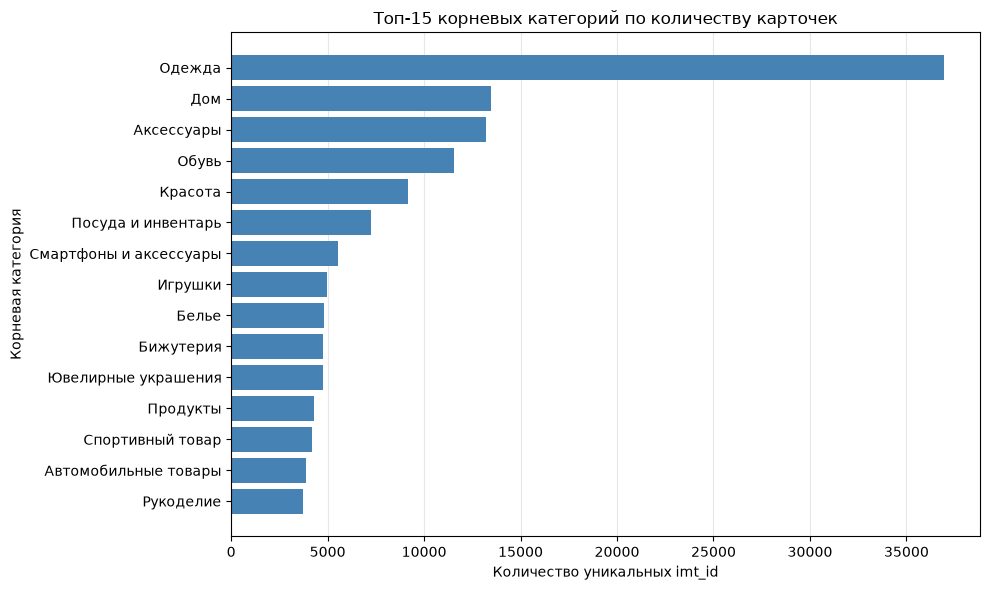

In [64]:
# Топ-15 корневых категорий по количеству уникальных карточек
top_categories = root_categories.head(15).sort_values("cards")

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    top_categories.index,
    top_categories["cards"],
    color="steelblue",
)

ax.set_title("Топ-15 корневых категорий по количеству карточек")
ax.set_xlabel("Количество уникальных imt_id")
ax.set_ylabel("Корневая категория")
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [65]:
# Исключаем категории с пустыми названиями из этой проверки
category_counts = subject_categories.reset_index()

category_counts = category_counts[
    category_counts["subj_root_name"].str.strip().ne("")
    & category_counts["subj_name"].str.strip().ne("")
]

# Категории, содержащие одну или две уникальные карточки
rare_categories = category_counts[
    category_counts["cards"] <= 2
].sort_values(["cards", "subj_root_name", "subj_name"])

print("Всего пар «корневая — предметная категория»:", len(category_counts))
print("Категорий с 1–2 карточками:", len(rare_categories))
print(
    "Доля редких категорий, %:",
    round(len(rare_categories) / len(category_counts) * 100, 2),
)

display(rare_categories.head(20))

Всего пар «корневая — предметная категория»: 3251
Категорий с 1–2 карточками: 822
Доля редких категорий, %: 25.28


,subj_root_name,subj_name,rows,cards
2725,Автомобильные товары,Аварийное оборудование,1,1
3221,Автомобильные товары,Автокружки,4,1
3222,Автомобильные товары,Аксессуары для автокресел,6,1
3223,Автомобильные товары,Антидождь,1,1
3224,Автомобильные товары,Антипробуксовочные приспособления,1,1
2726,Автомобильные товары,Блоки розжига ксенона,1,1
3250,Автомобильные товары,Блоки управления стеклоподъемниками,1,1
3249,Автомобильные товары,Велобагажники на авто,1,1
3248,Автомобильные товары,Воронки автомобильные,1,1
3247,Автомобильные товары,Датчики положения коленвала,1,1


In [66]:
# Длина текстов по всем строкам исходного каталога
text_lengths = pd.DataFrame(index=df_raw.index)

for column in ["imt_name", "description"]:
    text = df_raw[column].fillna("").str.strip()

    text_lengths[f"{column}_chars"] = text.str.len()
    text_lengths[f"{column}_words"] = text.str.split().str.len()

# Общая статистика, включая пустые тексты
print("Длины текстов, включая пустые:")
display(
    text_lengths.describe(
        percentiles=[0.5, 0.9, 0.95, 0.99]
    ).round(1)
)

# Отдельно — только заполненные описания
print("Длины непустых описаний:")
display(
    text_lengths.loc[
        text_lengths["description_chars"] > 0,
        ["description_chars", "description_words"],
    ].describe(
        percentiles=[0.5, 0.9, 0.95, 0.99]
    ).round(1)
)

Длины текстов, включая пустые:


,imt_name_chars,imt_name_words,description_chars,description_words
count,200000.0,200000.0,200000.0,200000.0
mean,32.9,4.8,372.0,50.4
std,24.0,3.6,472.8,64.6
min,0.0,0.0,0.0,0.0
50%,31.0,4.0,227.0,31.0
90%,65.0,10.0,934.0,125.0
95%,80.0,12.0,1081.0,152.0
99%,97.0,15.0,2065.0,289.0
max,121.0,31.0,5000.0,754.0


Длины непустых описаний:


,description_chars,description_words
count,142491.0,142491.0
mean,522.1,70.7
std,485.2,66.5
min,1.0,1.0
50%,398.0,53.0
90%,988.0,135.0
95%,1324.0,188.0
99%,2353.0,321.0
max,5000.0,754.0


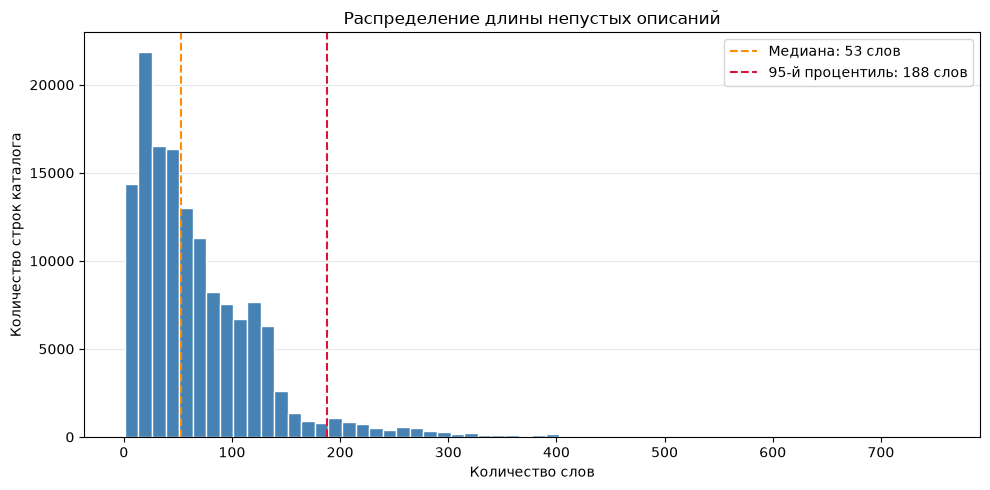

In [67]:
# Длины только непустых описаний
description_words = text_lengths.loc[
    text_lengths["description_chars"] > 0,
    "description_words",
]

median_words = description_words.median()
p95_words = description_words.quantile(0.95)

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    description_words,
    bins=60,
    color="steelblue",
    edgecolor="white",
)

ax.axvline(
    median_words,
    color="darkorange",
    linestyle="--",
    label=f"Медиана: {median_words:.0f} слов",
)
ax.axvline(
    p95_words,
    color="crimson",
    linestyle="--",
    label=f"95-й процентиль: {p95_words:.0f} слов",
)

ax.set_title("Распределение длины непустых описаний")
ax.set_xlabel("Количество слов")
ax.set_ylabel("Количество строк каталога")
ax.legend()
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [68]:
# Выбираем 20 случайных уникальных карточек для ручного просмотра
sample_cards = (
    df_raw.drop_duplicates(subset="imt_id")
    .sample(n=20, random_state=SEED)
)

for number, (_, row) in enumerate(sample_cards.iterrows(), start=1):
    print(f"\n{'=' * 70}")
    print(f"Карточка {number} | imt_id: {row['imt_id']}")
    print("Название:", row["imt_name"])
    print("Корневая категория:", row["subj_root_name"])
    print("Предметная категория:", row["subj_name"])
    print("Бренд:", row["brand_name"])
    print("Цвет:", row["nm_colors_names"])
    print("Описание:", row["description"])


Карточка 1 | imt_id: 10098093
Название: Питательная маска для волос с маслом кокоса и протеинами, 60 г
Корневая категория: Красота
Предметная категория: Маски косметические
Бренд: Palmer's
Цвет: 
Описание: Интенсивная маска для питания, укрепления и восстановления сухих, поврежденных волос, обогащенная натуральным кокосовым маслом, а также маслом Моной де Таити, настоянного на лепестках цветов Тиаре.Натуральные компоненты - витамин Е, кератиновый протеин, протеины шелка и кокосовое молоко- способствуют глубокому увлажнению и питанию сухих повреждённых волос, возвращают им блеск и сияние.БЕЗ парабенов, фталатов, сульфатов и глютена

Карточка 2 | imt_id: 10149588
Название: Браслет из цветов Девичник, для девичника, для выпускного, для выступления
Корневая категория: Бижутерия
Предметная категория: Браслеты
Бренд: АксМода
Цвет: бежевый, кремовый
Описание: Браслет с цветами на руку. Основа: Атласная лента и декоративные листочки. Декор: Композиция из цветов и дополнительные элементы (ягод

### Выводы по ручному просмотру карточек
Просмотрел 20 случайных карточек. У 6 отсутствует описание,
а некоторые названия содержат только тип товара: «Ботинки», «Лонгслив».

В текстах встречаются рекламные фразы, ссылки на другие товары,
лишние пробелы, пустые кавычки и склеенные предложения.
HTML-тегов в этих 20 карточках не обнаружил.

Цвет не всегда указан в названии. Числа и латиница могут обозначать
размеры и модели, поэтому удалять их полностью нельзя.
Полезные характеристики встречаются и в конце длинных описаний.

При очистке нормализую пробелы и сохраняю характеристики товаров.
Карточки без описания, но с названием оставляю.

In [70]:
# Связь карточек с корневыми категориями
card_categories = df_raw[
    ["imt_id", "subj_root_name"]
].drop_duplicates()

# Категории товаров из тренировочной разметки
train_categories = queries_train.merge(
    card_categories,
    left_on="item_id",
    right_on="imt_id",
    how="left",
)

# Покрытие категорий тренировочной разметкой
train_coverage = (
    train_categories.groupby("subj_root_name")
    .agg(
        queries=("query_id", "nunique"),
        items=("item_id", "nunique"),
    )
    .sort_values("queries", ascending=False)
)

display(train_coverage.head(20))

,queries,items
subj_root_name,,
Одежда,489,1689
Обувь,211,596


### Решения по результатам EDA

- **Категории:** «Одежда» и «Обувь» — 36 965 и 11 524 карточки.
  К ним относятся все товары тренировочной разметки.
- **Индексация:** одна запись на imt_id, поскольку разметка
  связана с карточками, а не отдельными артикулами.
- **Дубликаты:** для каждого imt_id выбираю строку с названием,
  затем с наиболее длинным описанием. При равенстве — по nm_id.
  После этого удаляю карточки без названия и описания.
- **Пропуски:** учитываем NaN, пустые строки и пробелы.
  Товары без описания сохраняем и отмечаем has_description.
- **Варианты product_text:** название; название + категория;
  название + категория + описание.
- **Основной вариант:** название + категория + описание:
  он сохраняет тип товара и подробные характеристики.
  Пустые поля пропускаем.
- **Бренд и цвет:** пока оставляем отдельными полями.
- **Очистка:** нормализуем пробелы и переносы строк,
  сохраняем числа, размеры и обозначения моделей.
- **Длина:** необходимость обрезки проверим токенизатором
  выбранной модели.

---

## Неделя 2 — базовый пайплайн и оценка качества

**Цель:** оперевшись на результаты EDA, создать работающий поиск и получить первые метрики качества.

Прежде чем реализовывать семантический поиск, основанный на эмбеддингах, нужно проверить, как справляется более простая модель, опирающаяся на TF-IDF. Простая модель нужна как baseline, без этой точки отсчёта результат невозможно интерпретировать.


### 1. Подготовка данных


Реализуйте решения недели 1:

1. Отфильтруйте выбранные категории.
2. Дедуплицируйте строки по `imt_id`. Сформулируйте правило, по которому будете определять, какую строку оставить. К примеру, можете оставить строку с самым информативным описанием. Ответ обоснуйте.
3. Отбросьте карточки, у которых пусты одновременно и `imt_name`, и `description`.
4. Напишите функцию очистки текста.
5. Соберите единый текст карточек в отдельной колонке `product_text`.

In [88]:
# Ваш код: фильтрация, дедупликация, отсев пустых, очистка, сборка product_text
SELECTED_CATEGORIES = ["Одежда", "Обувь"]
df_products = df_raw[df_raw["subj_root_name"].isin(SELECTED_CATEGORIES)].copy()
print("Строк после отбора категорий:", len(df_products))
print("Уникальных карточек:", df_products["imt_id"].nunique())

Строк после отбора категорий: 56503
Уникальных карточек: 48489


In [89]:
df_products["_has_name"] = df_products["imt_name"].fillna("").str.strip().ne("")
df_products["_description_length"] = df_products["description"].fillna("").str.strip().str.len()
df_products = (
    df_products.sort_values(
        ["imt_id", "_has_name", "_description_length", "nm_id"],
        ascending=[True, False, False, True],
        kind="stable"
    )
    .drop_duplicates(subset="imt_id", keep="first")
    .drop(columns=["_has_name", "_description_length"])
    .reset_index(drop=True)
)
print("Строк после дедупликации:", len(df_products))
print("Повторов imt_id:", df_products["imt_id"].duplicated().sum())

Строк после дедупликации: 48489
Повторов imt_id: 0


In [73]:
empty_text = (
    df_products["imt_name"].fillna("").str.strip().eq("")
    & df_products["description"].fillna("").str.strip().eq("")
)
print("Исключено карточек без текста:", empty_text.sum())
df_products = df_products.loc[~empty_text].copy().reset_index(drop=True)
df_products["has_description"] = df_products["description"].fillna("").str.strip().ne("")
print("Осталось карточек:", len(df_products))

Исключено карточек без текста: 113
Осталось карточек: 48376


In [74]:
import re
import html
def clean_text(value):
    if pd.isna(value):
        return ""
    text = html.unescape(str(value))
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"[\u200b-\u200d\ufeff]", "", text)
    text = re.sub(r"[\x00-\x1f\x7f]", " ", text)
    text = re.sub(r"(?<=[а-яёА-ЯЁ])\.(?=[А-ЯЁ])", ". ", text)
    text = text.replace('""', "")
    return re.sub(r"\s+", " ", text).strip()
for column in ["imt_name", "subj_name", "description"]:
    df_products[column] = df_products[column].map(clean_text)
df_products["has_description"] = df_products["description"].ne("")
display(df_products[["imt_name", "subj_name", "description"]].head())

,imt_name,subj_name,description
0,Платье,Платья,
1,Куртка,Куртки,
2,Сандалии,Сандалии,
3,Ботинки,Ботинки,
4,Сандалии,Сандалии,


In [75]:
text_columns = ["imt_name", "subj_name", "description"]
df_products["product_text"] = df_products[text_columns].apply(
    lambda row: "\n".join(value for value in row if value),
    axis=1
)
print("Пустых product_text:", df_products["product_text"].str.strip().eq("").sum())
for _, row in df_products.sample(n=5, random_state=SEED).iterrows():
    print(f"\nimt_id: {row['imt_id']}")
    print(row["product_text"])

Пустых product_text: 0

imt_id: 10178223
Атласная женская блузка
Рубашки
Атласная блузка красивого табачного цвета с длинными широкими рукавами. Элегантная модель, которая соберет на себе все взгляды.

imt_id: 1008592
Толстовка
Толстовки

imt_id: 10154123
Босоножки
Босоножки

imt_id: 10183931
Сандалии
Сандалии

imt_id: 10012374
Сабо открытые пантолеты натуральная кожа на низкой подошве
Сабо
ПОЖАЛУЙСТА, пишите Ваши отзывы и замечания, нам это Важно и Вашу помощь оценят другие покупатели (+ к карме)))! Все наши женские ботинки, кроссовки, сабо, босоножки и туфли выполнены из натуральной кожи, натуральной замши и натурального меха (зимние) по лекалам итальянских дизайнеров, на производстве в Турции. Колодки адаптированы нашими технологами под российские стандарты и особенности стопы. Мы очень стараемся создавать удобные, красивые, яркие, трендовые модели из самых качественных материалов и делать их удобными и комфортными и Ваша помощь станет неоценимой! Лёгкие открытые сабо из натуральной

### Каталог для поиска и оценки

1. Посчитайте метрику при поиске по всему отфильтрованному каталогу. Например, вычислите NDCG@10 лексическим поиском на 100 запросах.
2. Выведите топ-10 для одного запроса и отметьте, какие товары есть в разметке, а каких нет. Выясните, в чём проблема.
3. Ограничьте каталог оценки пулом асессоров: возьмите из `wb_products_dedup.parquet` только список `imt_id` и оставьте в своём подготовленном каталоге пересечение с ним. Тексты и все признаки — ваши, из шага 1.
4. Пересчитайте метрику и сравните результаты.
5. Посмотрите на распределение `relevance` и число оценённых товаров на запрос. Проверьте, у всех ли запросов есть товары с `relevance` ≥ 2.

In [76]:
from sklearn.feature_extraction.text import TfidfVectorizer
full_catalog = df_products.copy().reset_index(drop=True)
full_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=100000,
    lowercase=True,
    norm="l2",
    dtype=np.float32
)
full_tfidf = full_vectorizer.fit_transform(full_catalog["product_text"])
print("Размер матрицы TF-IDF:", full_tfidf.shape)

Размер матрицы TF-IDF: (48376, 100000)


In [79]:
def search_lexical_full(query, top_k=10):
    if top_k < 1:
        raise ValueError("top_k должен быть положительным")
    query_vector = full_vectorizer.transform([clean_text(query)])
    scores = (full_tfidf @ query_vector.T).toarray().ravel()
    top_indices = np.argsort(-scores, kind="stable")[:top_k]
    result = full_catalog.iloc[top_indices][
        ["imt_id", "imt_name", "subj_name"]
    ].copy()
    result["score"] = scores[top_indices]
    return result.reset_index(drop=True)
example_query = queries_train["query_text"].iloc[0]
# print("Запрос:", example_query)
# display(search_lexical_full(example_query))

example_query_id = queries_train["query_id"].iloc[0]
example_labels = queries_train.loc[
    queries_train["query_id"].eq(example_query_id),
    ["item_id", "relevance"]
]
example_results = search_lexical_full(example_query).merge(
    example_labels,
    left_on="imt_id",
    right_on="item_id",
    how="left",
    validate="one_to_one"
).drop(columns="item_id")
example_results["is_assessed"] = example_results["relevance"].notna()
display(example_results)
print("Оценённых товаров в топ-10:", example_results["is_assessed"].sum())

,imt_id,imt_name,subj_name,score,relevance,is_assessed
0,1018103,Жилеты,Жилеты,0.44404,NaN,False
1,10002776,Жилеты,Жилеты,0.44404,NaN,False
2,10002778,Жилеты,Жилеты,0.44404,NaN,False
3,10031391,Жилеты,Жилеты,0.44404,NaN,False
4,10076189,Жилеты,Жилеты,0.44404,1.0,True
5,10076190,Жилеты,Жилеты,0.44404,NaN,False
6,10089945,Жилеты,Жилеты,0.44404,NaN,False
7,10089962,Жилеты,Жилеты,0.44404,NaN,False
8,10114374,Жилеты,Жилеты,0.44404,NaN,False
9,10114375,Жилеты,Жилеты,0.44404,NaN,False


Оценённых товаров в топ-10: 1


In [80]:
def ndcg_at_k(item_ids, relevance_map, k=10):
    relevance = np.array([relevance_map.get(item_id, 0) for item_id in item_ids[:k]])
    ideal = np.array(sorted(relevance_map.values(), reverse=True)[:k])
    dcg = np.sum((2.0**relevance - 1) / np.log2(np.arange(len(relevance)) + 2))
    idcg = np.sum((2.0**ideal - 1) / np.log2(np.arange(len(ideal)) + 2))
    return float(dcg / idcg) if idcg > 0 else 0.0
eval_queries = (
    queries_train[["query_id", "query_text"]]
    .drop_duplicates()
    .sample(n=100, random_state=SEED)
)
relevance_maps = {
    query_id: group.set_index("item_id")["relevance"].to_dict()
    for query_id, group in queries_train.groupby("query_id")
}
full_ndcg_scores = []
for row in eval_queries.itertuples(index=False):
    item_ids = search_lexical_full(row.query_text, top_k=10)["imt_id"].tolist()
    full_ndcg_scores.append(ndcg_at_k(item_ids, relevance_maps[row.query_id], k=10))
print("Запросов:", len(full_ndcg_scores))
print("NDCG@10 по полному каталогу:", round(np.mean(full_ndcg_scores), 4))

Запросов: 100
NDCG@10 по полному каталогу: 0.072


In [81]:
if not ASSESSED_POOL_PATH.exists():
    s3.download_file(source_bucket, ASSESSED_POOL_PATH.name, str(ASSESSED_POOL_PATH))
assessed_ids = pd.read_parquet(ASSESSED_POOL_PATH, columns=["imt_id"])["imt_id"]
eval_catalog = full_catalog[
    full_catalog["imt_id"].isin(assessed_ids)
].copy().reset_index(drop=True)
print("Карточек в исходном пуле:", assessed_ids.nunique())
print("Карточек в каталоге оценки:", len(eval_catalog))
print(
    "Товаров train вне каталога оценки:",
    len(set(queries_train["item_id"]) - set(eval_catalog["imt_id"]))
)

Карточек в исходном пуле: 4256
Карточек в каталоге оценки: 4256
Товаров train вне каталога оценки: 0


In [82]:
eval_mask = full_catalog["imt_id"].isin(assessed_ids).to_numpy()
eval_tfidf = full_tfidf[eval_mask]
def search_lexical(query, top_k=10):
    if top_k < 1:
        raise ValueError("top_k должен быть положительным")
    query_vector = full_vectorizer.transform([clean_text(query)])
    scores = (eval_tfidf @ query_vector.T).toarray().ravel()
    top_indices = np.argsort(-scores, kind="stable")[:top_k]
    result = eval_catalog.iloc[top_indices][
        ["imt_id", "imt_name", "subj_name"]
    ].copy()
    result["score"] = scores[top_indices]
    return result.reset_index(drop=True)
eval_ndcg_scores = []
for row in eval_queries.itertuples(index=False):
    item_ids = search_lexical(row.query_text, top_k=10)["imt_id"].tolist()
    eval_ndcg_scores.append(ndcg_at_k(item_ids, relevance_maps[row.query_id], k=10))
display(pd.DataFrame({
    "Каталог": ["Полный", "Пул оценки"],
    "Карточек": [len(full_catalog), len(eval_catalog)],
    "NDCG@10": [np.mean(full_ndcg_scores), np.mean(eval_ndcg_scores)]
}))

,Каталог,Карточек,NDCG@10
0,Полный,48376,0.072021
1,Пул оценки,4256,0.463402


In [83]:
RELEVANCE_THRESHOLD = 2
print("Распределение оценок:")
display(
    queries_train["relevance"].value_counts().sort_index()
    .rename_axis("relevance").to_frame("Количество")
)
items_per_query = queries_train.groupby("query_id")["item_id"].nunique()
print("Оценённых товаров на запрос:")
display(items_per_query.describe().round(2))
relevant_per_query = (
    queries_train.assign(is_relevant=queries_train["relevance"] >= RELEVANCE_THRESHOLD)
    .groupby("query_id")["is_relevant"].sum()
)
print("Запросов без товаров с relevance >= 2:", relevant_per_query.eq(0).sum())

Распределение оценок:


,Количество
relevance,
1,9652
2,1101
3,700


Оценённых товаров на запрос:


count    700.00
mean      16.36
std        5.42
min        1.00
25%       14.00
50%       16.00
75%       19.00
max       31.00
Name: item_id, dtype: float64

Запросов без товаров с relevance >= 2: 0


### 2. Модели поиска

Реализуйте два поисковых движка с одинаковым интерфейсом. Это позволит прогнать оба через одну функцию оценки:

In [90]:
def search_xxx(query: str, top_k: int = 10) -> pd.DataFrame:
    """Возвращает top_k товаров с колонками imt_id, imt_name, subj_name, score."""


Реализуйте лексический baseline на TF-IDF:

In [91]:
# Ваш код: TF-IDF-индекс и search_lexical
# Индекс и функция реализованы выше для сравнения каталогов.
display(search_lexical(example_query, top_k=5))

,imt_id,imt_name,subj_name,score
0,10076189,Жилеты,Жилеты,0.444040
1,1016032,Жилет PHILOMENE,Жилеты,0.389681
2,10001023,Жилет Юнона,Жилеты,0.389681
3,1000988,Жилет,Жилеты,0.310180
4,10077041,"Платье вечернее ""Jennifer""/Летний сарафан/Бело...",Платья,0.307311


Реализуйте семантический поиск:

In [93]:
# Ваш код: эмбеддинги и search_semantic
from sentence_transformers import SentenceTransformer
MODEL_NAME = "intfloat/multilingual-e5-small"
model = SentenceTransformer(MODEL_NAME, device="cpu")
print("Модель:", MODEL_NAME)
print("Лимит токенов:", model.max_seq_length)
print("Размерность вектора:", model.get_embedding_dimension())

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1030.28it/s]


Модель: intfloat/multilingual-e5-small
Лимит токенов: 512
Размерность вектора: 384


In [85]:
passages = ["passage: " + text for text in eval_catalog["product_text"]]
token_lengths = []
for start in range(0, len(passages), 64):
    encoded = model.tokenizer(
        passages[start:start + 64],
        truncation=False,
        padding=False,
        return_length=True
    )
    token_lengths.extend(encoded["length"])
token_lengths = np.array(token_lengths)
print("Карточек:", len(token_lengths))
print("Максимальная длина в токенах:", token_lengths.max())
print("Превышают лимит:", (token_lengths > model.max_seq_length).sum())
print("Доля превышающих лимит, %:", round(
    (token_lengths > model.max_seq_length).mean() * 100, 2
))

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (548 > 512). Running this sequence through the model will result in indexing errors


Карточек: 4256
Максимальная длина в токенах: 1134
Превышают лимит: 53
Доля превышающих лимит, %: 1.25


In [86]:
model.max_seq_length = 512
product_embeddings = model.encode(
    passages,
    batch_size=16,
    normalize_embeddings=True,
    convert_to_numpy=True,
    show_progress_bar=True
)
ARTIFACTS_DIR = Path("artifacts")
ARTIFACTS_DIR.mkdir(exist_ok=True)
np.save(ARTIFACTS_DIR / "product_embeddings_e5_small.npy", product_embeddings)
np.save(ARTIFACTS_DIR / "product_ids_e5_small.npy", eval_catalog["imt_id"].to_numpy())
print("Размер матрицы эмбеддингов:", product_embeddings.shape)

Batches: 100%|██████████| 266/266 [04:01<00:00,  1.10it/s]

Размер матрицы эмбеддингов: (4256, 384)


In [87]:
def search_semantic(query, top_k=10):
    if top_k < 1:
        raise ValueError("top_k должен быть положительным")
    query_embedding = model.encode(
        "query: " + clean_text(query),
        normalize_embeddings=True,
        convert_to_numpy=True,
        show_progress_bar=False
    )
    scores = product_embeddings @ query_embedding
    top_indices = np.argsort(-scores, kind="stable")[:top_k]
    result = eval_catalog.iloc[top_indices][
        ["imt_id", "imt_name", "subj_name"]
    ].copy()
    result["score"] = scores[top_indices]
    return result.reset_index(drop=True)
print("Запрос:", example_query)
display(search_semantic(example_query))

Запрос: жилеты на пуговицах


,imt_id,imt_name,subj_name,score
0,10096636,Жилет для девочки,Жилеты,0.856990
1,10092580,Атласное платье на пуговичках,Платья,0.855234
2,100433,Жилетка,Жилеты,0.853219
3,10089060,Жилет утепленный,Жилеты,0.851672
4,10086438,Жилеты,Жилеты,0.850883
5,10136994,Пиджак женский,Жакеты,0.849808
6,10088082,Куртка джинсовая,Пиджаки,0.849802
7,10088093,Худи укороченое без рукавов,Худи,0.848963
8,10028340,Жилет,Жилеты,0.846742
9,1016032,Жилет PHILOMENE,Жилеты,0.846488


Прогоните 3–5 запросов вручную и сравните выдачу обоих подходов. Это самый простой способ поймать грубые ошибки до подсчёта метрик.

In [94]:
# Ваш код
sample_queries = (
    queries_train[["query_id", "query_text"]]
    .drop_duplicates()
    .sample(n=3, random_state=SEED)
)
for row in sample_queries.itertuples(index=False):
    print("\nЗапрос:", row.query_text)
    for method_name, search_function in [
        ("Лексический поиск", search_lexical),
        ("Семантический поиск", search_semantic)
    ]:
        result = search_function(row.query_text, top_k=5)
        result["relevance"] = result["imt_id"].map(relevance_maps[row.query_id])
        print(method_name)
        display(result)


Запрос: топы cop copine
Лексический поиск


,imt_id,imt_name,subj_name,score,relevance
0,10016977,Топы,Топы,0.766925,1
1,10047446,Топ - TROPICO,Топы,0.722997,1
2,10150664,Топ - CINTIA,Топы,0.722997,1
3,101146,Топ,Топы,0.561121,1
4,10002416,Майка Сердце,Топы,0.456532,1


Семантический поиск


,imt_id,imt_name,subj_name,score,relevance
0,10150664,Топ - CINTIA,Топы,0.874794,1.0
1,10002416,Майка Сердце,Топы,0.870075,1.0
2,10042858,Майка,Топы,0.865414,1.0
3,10047446,Топ - TROPICO,Топы,0.864523,1.0
4,10034209,Куртка,Кофты,0.863276,NaN



Запрос: худи mego as
Лексический поиск


,imt_id,imt_name,subj_name,score,relevance
0,1004435,Худи,Худи,0.865283,1
1,10142636,Худи Raava,Худи,0.731015,1
2,10089828,Худи UFC,Худи,0.717322,1
3,10080294,Худи Oversize,Худи,0.592081,1
4,10088093,Худи укороченое без рукавов,Худи,0.524681,1


... (2 outputs left out)


Запрос: бриджи зуавы
Лексический поиск


,imt_id,imt_name,subj_name,score,relevance
0,1003861,Бриджи,Бриджи,0.470974,1
1,10124357,Бриджи Тропики,Бриджи,0.347153,1
2,10000043,Бриджи/большие размеры/стрейч/ажур,Бриджи,0.323375,1
3,10005760,Бриджи женские/большого размера/Облегающие брю...,Бриджи,0.228958,1
4,10127189,Бриджи детские,Брюки,0.213279,1


Семантический поиск


,imt_id,imt_name,subj_name,score,relevance
0,10127189,Бриджи детские,Брюки,0.869414,1.0
1,10046070,Бриджи женские,Капри,0.863046,1.0
2,10096870,Зуавы,Бриджи,0.859113,3.0
3,10090353,Кардиган ZOJA,Кардиганы,0.857642,NaN
4,10090874,Брюки SOVA LINA,Брюки,0.854272,NaN


### 3. Оценка качества решений

Реализуйте метрики Precision@K, Recall@K, MRR, NDCG@K, HitRate@K.

Три ключевые особенности, которые надо учесть при расчёте:

1. Порог бинаризации. Precision@K, Recall@K, MRR, HitRate@K бинарны, а шкала `relevance` — от `0` до `3`. С какой оценки товар считается релевантным? Вынесите порог в параметр, а не константу внутри функции.
2. NDCG считайте по полной шкале 0–3 (`gain = 2^rel - 1`), а не по бинаризованной, иначе теряется смысл градуированной разметки.
3. Неразмеченные товары в выдаче трактуйте как нерелевантные (`relevance_map.get(item_id, 0)`).

Выводы запишите в Markdown-ячейке и рабочем файле Markdown.

In [95]:
RELEVANCE_THRESHOLD = 2   # Ваше решение, его нужно обосновать

# Ваш код для работы с метриками
def calculate_metrics(item_ids, relevance_map, k, threshold=2):
    top_ids = item_ids[:k]
    hits = np.array([
        relevance_map.get(item_id, 0) >= threshold
        for item_id in top_ids
    ], dtype=bool)
    total_relevant = sum(rel >= threshold for rel in relevance_map.values())
    positions = np.flatnonzero(hits)
    return {
        f"Precision@{k}": hits.sum() / k,
        f"Recall@{k}": hits.sum() / total_relevant if total_relevant else 0.0,
        f"MRR@{k}": 1.0 / (positions[0] + 1) if len(positions) else 0.0,
        f"NDCG@{k}": ndcg_at_k(item_ids, relevance_map, k),
        f"HitRate@{k}": float(hits.any())
    }
display(pd.Series(calculate_metrics(
    [10, 20, 30],
    {10: 0, 20: 3, 30: 2, 40: 2},
    k=3,
    threshold=RELEVANCE_THRESHOLD
)))

Precision@3    0.666667
Recall@3       0.666667
MRR@3          0.500000
NDCG@3         0.569290
HitRate@3      1.000000
dtype: float64

In [96]:
K_VALUES = [1, 3, 5, 10]
evaluation_queries = queries_train[["query_id", "query_text"]].drop_duplicates()
metrics_rows = []
for row in evaluation_queries.itertuples(index=False):
    for method, search_function in [
        ("TF-IDF", search_lexical),
        ("E5-small", search_semantic)
    ]:
        item_ids = search_function(row.query_text, top_k=max(K_VALUES))["imt_id"].tolist()
        result = {"method": method, "query_id": row.query_id}
        for k in K_VALUES:
            result.update(calculate_metrics(
                item_ids,
                relevance_maps[row.query_id],
                k=k,
                threshold=RELEVANCE_THRESHOLD
            ))
        metrics_rows.append(result)
metrics_by_query = pd.DataFrame(metrics_rows)
metrics_summary = metrics_by_query.groupby("method").mean(numeric_only=True)
display(metrics_summary.round(4).T)

method,E5-small,TF-IDF
Precision@1,0.3871,0.0729
Recall@1,0.2213,0.0391
MRR@1,0.3871,0.0729
NDCG@1,0.3347,0.1818
HitRate@1,0.3871,0.0729
Precision@3,0.2881,0.0748
Recall@3,0.4104,0.1051
MRR@3,0.4807,0.1186
NDCG@3,0.4368,0.2896
HitRate@3,0.5971,0.1800


### Выводы по первой итерации
Сравнил два метода на 700 тренировочных запросах и каталоге
из 4 256 карточек. Для Precision, Recall, MRR@K и HitRate
релевантными считаю оценки 2 и 3. Для NDCG использую всю шкалу.

E5-small показал лучшие результаты по всем рассчитанным метрикам.
NDCG@10 — 0,4741 против 0,4364 у TF-IDF,
Recall@10 — 0,5942 против 0,3137.
Особенно заметна разница на первой позиции:
Precision@1 — 0,3871 против 0,0729.

В просмотренных примерах оба метода плохо справились с запросами
по бренду. При этом E5-small нашёл «Зуавы» на третьем месте,
но иногда возвращал товары другой категории.
В следующих экспериментах проверю добавление бренда,
другой состав product_text и гибридный поиск.

Оценка ограничена синтетической разметкой и пулом карточек.
Неразмеченные товары получают 0, даже если могут подходить запросу.
Тестовую выборку для расчёта метрик и настройки не использовал.

---

## Неделя 3 — эксперименты, дообучение и MLflow

**Цель:** проверить гипотезы о том, как можно улучшить систему поиска, зафиксировать эксперименты, дать рекомендации бизнесу.

**Главное правило:** «один эксперимент — одна гипотеза — одно изменение». Если поменять сразу модель, шаблон текста и параметры векторизации, прирост будет невозможно объяснить и повторить.

### 1. Эксперименты по улучшению

Проведите минимум три эксперимента. Оформляйте каждый по схеме:

- **Гипотеза** — ваше предположение и его обоснование. Причины «хочу попробовать другую модель» недостаточно, нужны объяснения такого типа: «Модель с большим окном улучшит поиск товаров с длинными описаниями, потому что в EDA я видел, что X% описаний обрезаются по лимиту токенов».
- **Что меняется** — ровно один компонент относительно baseline.
- **Результат** — метрики на тех же данных, с тем же порогом и теми же K.
- **Вывод** — принимаем или отклоняем гипотезу. Что это говорит о данных?

Придумывайте гипотезы, опираясь на ошибки, которые обнаружили на неделе 2. Если выбранная модель путает смежные категории, попробуйте проверить, решит ли проблему добавление данных из `subj_name` в общий текст карточки. Другой пример: если лексический поиск обходит семантический на точных названиях, а семантический выигрывает у лексического, когда дело доходит до неточных формулировок, — это повод попробовать реализовать гибридный поиск.

Направления для разработки гипотез:

- изменить шаблон `product_text`;
- попробовать другую модель эмбеддингов;
- дообучить модели;
- реализовать гибридный поиск с помощью взвешенной суммы скоров или реранкинга семантикой поверх лексического отбора;
- ввести лемматизацию и стоп-слова для TF-IDF;
- изменить параметры векторизации.

In [102]:
# Эксперимент 1
# Гипотеза: добавление бренда улучшит поиск по запросам с названием бренда.
# Что меняем: добавляем brand_name в product_text, остальные настройки сохраняем.

# Ваш код
eval_catalog_brand = eval_catalog.copy()
eval_catalog_brand["brand_name"] = eval_catalog_brand["brand_name"].map(clean_text)
eval_catalog_brand["product_text"] = eval_catalog_brand.apply(
    lambda row: "\n".join(
        value for value in [
            row["imt_name"], row["subj_name"], row["brand_name"], row["description"]
        ] if value
    ),
    axis=1
)
for _, row in eval_catalog_brand.sample(n=3, random_state=SEED).iterrows():
    print(f"\nimt_id: {row['imt_id']}")
    print(row["product_text"])


imt_id: 1008644
халат
Халаты банные
Taubert

imt_id: 10026742
Рубашка на кнопках
Рубашки
CHMELAN
Рубашка свободного кроя. Два накладных кармана с клапаном. Кнопки серебристого цвета. Рукав регулируется шлевкой на кнопочке.

imt_id: 10116692
Ночная сорочка для девочки Детская
Ночные сорочки
Alena Alenkina
Трикотажная ночная сорочка для девочек с коротким рукавом - комфортная детская одежда для сна. Ночнушка из 100% хлопка, ткань кулирка. Ночная рубашка с ярким принтом отлично подойдет для дома и отдыха, дачи и детского садика, как легкое платье на лето и модная пижама для девочки. Сорочка приятная к телу, идеально для комфортного сна ребенка и как домашняя одежда. Маленькая модница оценит подарок в виде яркой пижамы на любой праздник: 8 марта, День рождение, новый год. Сорочки на возраст 6, 7, 8, 9, 10, 11, 12, 13, 14 лет. На рост 104 110 116 122 128 134 140 146 152 158 164. В каталоге нашего бренда Alena Alenkina (Алена Аленкина) представлена летняя и домашняя детская одежда для девоч

In [103]:
passages_brand = ["passage: " + text for text in eval_catalog_brand["product_text"]]
product_embeddings_brand = model.encode(
    passages_brand,
    batch_size=16,
    normalize_embeddings=True,
    convert_to_numpy=True,
    show_progress_bar=True
)
ARTIFACTS_DIR.mkdir(exist_ok=True)
np.save(ARTIFACTS_DIR / "product_embeddings_e5_brand.npy", product_embeddings_brand)
np.save(ARTIFACTS_DIR / "product_ids_e5_brand.npy", eval_catalog_brand["imt_id"].to_numpy())
print("Размер матрицы:", product_embeddings_brand.shape)

Batches: 100%|██████████| 266/266 [05:55<00:00,  1.33s/it]

Размер матрицы: (4256, 384)


In [104]:
def search_semantic_brand(query, top_k=10):
    if top_k < 1:
        raise ValueError("top_k должен быть положительным")
    query_embedding = model.encode(
        "query: " + clean_text(query),
        normalize_embeddings=True,
        convert_to_numpy=True,
        show_progress_bar=False
    )
    scores = product_embeddings_brand @ query_embedding
    top_indices = np.argsort(-scores, kind="stable")[:top_k]
    result = eval_catalog_brand.iloc[top_indices][
        ["imt_id", "imt_name", "subj_name"]
    ].copy()
    result["score"] = scores[top_indices]
    return result.reset_index(drop=True)
metrics_rows_brand = []
for row in evaluation_queries.itertuples(index=False):
    item_ids = search_semantic_brand(row.query_text, top_k=max(K_VALUES))["imt_id"].tolist()
    result = {"method": "E5-small + brand", "query_id": row.query_id}
    for k in K_VALUES:
        result.update(calculate_metrics(
            item_ids,
            relevance_maps[row.query_id],
            k=k,
            threshold=RELEVANCE_THRESHOLD
        ))
    metrics_rows_brand.append(result)
metrics_by_query_brand = pd.DataFrame(metrics_rows_brand)
metrics_summary_brand = metrics_by_query_brand.groupby("method").mean(numeric_only=True)
display(pd.concat([
    metrics_summary.loc[["E5-small"]],
    metrics_summary_brand
]).round(4).T)

method,E5-small,E5-small + brand
Precision@1,0.3871,0.5743
Recall@1,0.2213,0.3753
MRR@1,0.3871,0.5743
NDCG@1,0.3347,0.4857
HitRate@1,0.3871,0.5743
Precision@3,0.2881,0.3600
Recall@3,0.4104,0.5877
MRR@3,0.4807,0.6662
NDCG@3,0.4368,0.5631
HitRate@3,0.5971,0.7814


**Вывод по эксперименту 1.**
Добавление бренда улучшило качество поиска: NDCG@10 вырос
с 0,4741 до 0,5633, а Recall@10 — с 0,5942 до 0,7674.
Доля запросов с релевантным товаром на первом месте увеличилась
с 38,71% до 57,43%. Гипотеза подтверждается на тренировочном
наборе. Влияние именно на брендовые запросы отдельно не измерял.

In [105]:
# Эксперимент 2
# Гипотеза: исключение описания уменьшит рекламный шум и улучшит поиск.
# Что меняем: убираем description из базового текста, бренд не добавляем.
# Ваш код
eval_catalog_short = eval_catalog.copy()
eval_catalog_short["product_text"] = eval_catalog_short.apply(
    lambda row: "\n".join(
        value for value in [row["imt_name"], row["subj_name"]] if value
    ),
    axis=1
)
display(eval_catalog_short[["imt_id", "product_text"]].head())

,imt_id,product_text
0,100037,Ботинки\nБотинки
1,100089,Ветровка\nВетровки
2,100098,Куртка\nКуртки
3,100146,Пальто\nПальто
4,100165,Куртка горнолыжная\nКуртки


In [106]:
passages_short = ["passage: " + text for text in eval_catalog_short["product_text"]]
product_embeddings_short = model.encode(
    passages_short,
    batch_size=16,
    normalize_embeddings=True,
    convert_to_numpy=True,
    show_progress_bar=True
)
ARTIFACTS_DIR.mkdir(exist_ok=True)
np.save(ARTIFACTS_DIR / "product_embeddings_e5_short.npy", product_embeddings_short)
np.save(ARTIFACTS_DIR / "product_ids_e5_short.npy", eval_catalog_short["imt_id"].to_numpy())
print("Размер матрицы:", product_embeddings_short.shape)

Batches: 100%|██████████| 266/266 [01:07<00:00,  3.92it/s]

Размер матрицы: (4256, 384)


In [107]:
def search_semantic_short(query, top_k=10):
    if top_k < 1:
        raise ValueError("top_k должен быть положительным")
    query_embedding = model.encode(
        "query: " + clean_text(query),
        normalize_embeddings=True,
        convert_to_numpy=True,
        show_progress_bar=False
    )
    scores = product_embeddings_short @ query_embedding
    top_indices = np.argsort(-scores, kind="stable")[:top_k]
    result = eval_catalog_short.iloc[top_indices][
        ["imt_id", "imt_name", "subj_name"]
    ].copy()
    result["score"] = scores[top_indices]
    return result.reset_index(drop=True)
metrics_rows_short = []
for row in evaluation_queries.itertuples(index=False):
    item_ids = search_semantic_short(row.query_text, top_k=max(K_VALUES))["imt_id"].tolist()
    result = {"method": "E5-small short", "query_id": row.query_id}
    for k in K_VALUES:
        result.update(calculate_metrics(
            item_ids,
            relevance_maps[row.query_id],
            k=k,
            threshold=RELEVANCE_THRESHOLD
        ))
    metrics_rows_short.append(result)
metrics_by_query_short = pd.DataFrame(metrics_rows_short)
metrics_summary_short = metrics_by_query_short.groupby("method").mean(numeric_only=True)
display(pd.concat([
    metrics_summary.loc[["E5-small"]],
    metrics_summary_short
]).round(4).T)

method,E5-small,E5-small short
Precision@1,0.3871,0.1671
Recall@1,0.2213,0.0958
MRR@1,0.3871,0.1671
NDCG@1,0.3347,0.1790
HitRate@1,0.3871,0.1671
Precision@3,0.2881,0.1129
Recall@3,0.4104,0.1588
MRR@3,0.4807,0.2140
NDCG@3,0.4368,0.2268
HitRate@3,0.5971,0.2743


**Вывод по эксперименту 2.**
Без описания NDCG@10 снизился с 0,4741 до 0,2573,
Recall@10 — с 0,5942 до 0,2635. Гипотеза не подтвердилась.
Несмотря на рекламный шум, описание содержит полезные
характеристики, которых нет в названии и категории.
Оставляю описание в тексте товара.

In [108]:
# Эксперимент 3
# Гипотеза: сочетание лексического и семантического поиска улучшит выдачу.
# Что меняем: объединяем ранги TF-IDF и базового E5-small методом RRF.
# Ваш код
RRF_K = 60
def search_hybrid(query, top_k=10):
    if top_k < 1:
        raise ValueError("top_k должен быть положительным")
    scores = pd.Series(0.0, index=eval_catalog["imt_id"])
    for search_function in [search_lexical, search_semantic]:
        result = search_function(query, top_k=len(eval_catalog))
        ranks = np.arange(1, len(result) + 1)
        contribution = pd.Series(
            1.0 / (RRF_K + ranks),
            index=result["imt_id"]
        )
        scores = scores.add(contribution, fill_value=0)
    result = eval_catalog[["imt_id", "imt_name", "subj_name"]].copy()
    result["score"] = result["imt_id"].map(scores)
    return result.sort_values(
        "score", ascending=False, kind="stable"
    ).head(top_k).reset_index(drop=True)
display(search_hybrid(example_query))

,imt_id,imt_name,subj_name,score
0,100433,Жилетка,Жилеты,0.030798
1,1016032,Жилет PHILOMENE,Жилеты,0.030415
2,10001023,Жилет Юнона,Жилеты,0.029387
3,10089060,Жилет утепленный,Жилеты,0.028283
4,10086438,Жилеты,Жилеты,0.027433
5,10079050,Жилет вязаный длинный,Жилеты,0.025074
6,10096866,Жилет школьный,Жилеты,0.023740
7,1000988,Жилет,Жилеты,0.023259
8,10096636,Жилет для девочки,Жилеты,0.023060
9,10028340,Жилет,Жилеты,0.022757


In [109]:
metrics_rows_hybrid = []
for row in evaluation_queries.itertuples(index=False):
    item_ids = search_hybrid(row.query_text, top_k=max(K_VALUES))["imt_id"].tolist()
    result = {"method": "TF-IDF + E5 RRF", "query_id": row.query_id}
    for k in K_VALUES:
        result.update(calculate_metrics(
            item_ids,
            relevance_maps[row.query_id],
            k=k,
            threshold=RELEVANCE_THRESHOLD
        ))
    metrics_rows_hybrid.append(result)
metrics_by_query_hybrid = pd.DataFrame(metrics_rows_hybrid)
metrics_summary_hybrid = metrics_by_query_hybrid.groupby("method").mean(numeric_only=True)
all_metrics_summary = pd.concat([
    metrics_summary,
    metrics_summary_brand,
    metrics_summary_short,
    metrics_summary_hybrid
])
display(all_metrics_summary.round(4).T)

method,E5-small,TF-IDF,E5-small + brand,E5-small short,TF-IDF + E5 RRF
Precision@1,0.3871,0.0729,0.5743,0.1671,0.2729
Recall@1,0.2213,0.0391,0.3753,0.0958,0.1402
MRR@1,0.3871,0.0729,0.5743,0.1671,0.2729
NDCG@1,0.3347,0.1818,0.4857,0.1790,0.2831
HitRate@1,0.3871,0.0729,0.5743,0.1671,0.2729
Precision@3,0.2881,0.0748,0.3600,0.1129,0.2181
Recall@3,0.4104,0.1051,0.5877,0.1588,0.2934
MRR@3,0.4807,0.1186,0.6662,0.2140,0.3543
NDCG@3,0.4368,0.2896,0.5631,0.2268,0.4022
HitRate@3,0.5971,0.1800,0.7814,0.2743,0.4543


**Вывод по эксперименту 3.**
Гибридный поиск повысил NDCG@10 с 0,4741 до 0,5119,
но Recall@10 снизился с 0,5942 до 0,5504,
а Precision@1 — с 0,3871 до 0,2729.
Гипотеза подтвердилась только для NDCG@10:
общего улучшения по всем метрикам нет.

**Выбор решения.**
Для финального теста выбираю E5-small с добавлением бренда.
Этот вариант показал лучшие результаты по всем метрикам
на фиксированном наборе из 700 тренировочных запросов.
Модель, шаблон текста, порог 2 и K = 1, 3, 5, 10 фиксирую.
После оценки на test настройки менять не буду.

### 2. Финальный тест

Выборка `test` нужна для финальной проверки модели, когда конфигурация окончательно выбрана по результатам валидации. Каждый повторный прогон с подстройкой превращает `test` в ещё одну валидацию и обесценивает финальные показатели.

In [110]:
RUN_FINAL_TEST_EVAL = True

# Ваш код
if RUN_FINAL_TEST_EVAL:
    test_queries = queries_test[["query_id", "query_text"]].drop_duplicates()
    test_relevance_maps = {
        query_id: group.set_index("item_id")["relevance"].to_dict()
        for query_id, group in queries_test.groupby("query_id")
    }
    missing_test_items = set(queries_test["item_id"]) - set(eval_catalog_brand["imt_id"])
    assert not missing_test_items, "В каталоге оценки отсутствуют товары из test"
    metrics_rows_test = []
    for row in test_queries.itertuples(index=False):
        item_ids = search_semantic_brand(row.query_text, top_k=max(K_VALUES))["imt_id"].tolist()
        result = {"method": "E5-small + brand", "query_id": row.query_id}
        for k in K_VALUES:
            result.update(calculate_metrics(
                item_ids,
                test_relevance_maps[row.query_id],
                k=k,
                threshold=RELEVANCE_THRESHOLD
            ))
        metrics_rows_test.append(result)
    metrics_by_query_test = pd.DataFrame(metrics_rows_test)
    metrics_summary_test = metrics_by_query_test.groupby("method").mean(numeric_only=True)
    print("Тестовых запросов:", len(test_queries))
    display(metrics_summary_test.round(4).T)

Тестовых запросов: 300


method,E5-small + brand
Precision@1,0.5400
Recall@1,0.3854
MRR@1,0.5400
NDCG@1,0.4938
HitRate@1,0.5400
Precision@3,0.3289
Recall@3,0.5776
MRR@3,0.6222
NDCG@3,0.5625
HitRate@3,0.7267


На 300 тестовых запросах E5-small с добавлением бренда показал NDCG@10 = 0,5696 и Recall@10 = 0,7828. Эти значения близки к результатам на golden-сете: 0,5633 и 0,7674 соответственно.
В 54% запросов первый результат имеет релевантность не ниже 2. В 87% запросов хотя бы один такой товар есть в первой десятке. При этом Precision@10 составляет 0,1597: высокая полнота не означает, что вся десятка полезна.
Оценка выполнена на пуле из 4256 карточек с неполной разметкой. Товары без оценки при расчёте метрик считались нерелевантными, поэтому результаты зависят от покрытия разметки.

### 3. Трекинг экспериментов в MLflow

Каждая конфигурация — отдельный run с осмысленным именем (`semantic_bge_m3`, а не `run_7`).

Что логировать:
- Все параметры, известные до запуска, — метод, модель, шаблон текста, порог, размер каталога, сид.
- Метрики — все посчитанные значения.
- Артефакты — таблица метрик по запросам, сводная таблица, графики, копия данных, на которых проводилась проверка.

In [101]:
# Ваш код: подключение к MLflow из .env и логирование прогонов

import os
import mlflow
from dotenv import load_dotenv
load_dotenv(".env", override=True)
mlflow.set_tracking_uri(os.environ["MLFLOW_TRACKING_URI"])
EXPERIMENT_NAME = "semantic_search_project"
experiment = mlflow.set_experiment(EXPERIMENT_NAME)
print("Эксперимент:", experiment.name)
print("ID:", experiment.experiment_id)

Эксперимент: semantic_search_project
ID: 1


In [111]:
all_metrics_by_query = pd.concat([
    metrics_by_query,
    metrics_by_query_brand,
    metrics_by_query_short,
    metrics_by_query_hybrid
], ignore_index=True)
MLFLOW_ARTIFACTS_DIR = ARTIFACTS_DIR / "mlflow"
MLFLOW_ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)
queries_train.to_parquet(MLFLOW_ARTIFACTS_DIR / "golden_set.parquet", index=False)
all_metrics_by_query.to_csv(MLFLOW_ARTIFACTS_DIR / "metrics_by_query.csv", index=False)
all_metrics_summary.to_csv(MLFLOW_ARTIFACTS_DIR / "metrics_summary.csv")
metrics_by_query_test.to_csv(MLFLOW_ARTIFACTS_DIR / "test_metrics_by_query.csv", index=False)
metrics_summary_test.to_csv(MLFLOW_ARTIFACTS_DIR / "test_metrics_summary.csv")
print("Конфигураций:", all_metrics_by_query["method"].nunique())
print("Результаты сохранены:", MLFLOW_ARTIFACTS_DIR)

Конфигураций: 5
Результаты сохранены: artifacts\mlflow


In [113]:
load_dotenv(".env", override=True)
print("S3 для MLflow:", os.getenv("MLFLOW_S3_ENDPOINT_URL"))

S3 для MLflow: https://storage.yandexcloud.net


In [114]:
baseline_metrics = metrics_summary.loc["TF-IDF"]
baseline_by_query = metrics_by_query[
    metrics_by_query["method"].eq("TF-IDF")
]
baseline_path = MLFLOW_ARTIFACTS_DIR / "tfidf"
baseline_path.mkdir(exist_ok=True)
baseline_by_query.to_csv(baseline_path / "metrics_by_query.csv", index=False)
baseline_metrics.rename("value").to_csv(baseline_path / "metrics_summary.csv")
with mlflow.start_run(run_name="tfidf_baseline"):
    mlflow.log_params({
        "method": "lexical",
        "eval_split": "train_golden",
        "catalog_size": len(eval_catalog),
        "relevance_threshold": RELEVANCE_THRESHOLD,
        "k_values": str(K_VALUES),
        "mrr_cutoff": 10,
        "query_count": len(evaluation_queries),
        "product_text": "imt_name + subj_name + description",
        "embedding_model": "none",
        "ngram_range": str(full_vectorizer.ngram_range),
        "max_features": full_vectorizer.max_features,
        "lowercase": full_vectorizer.lowercase,
        "norm": full_vectorizer.norm,
        "vectorizer_fit_catalog_size": len(full_catalog)
    })
    mlflow.log_metrics({
        name.lower().replace("@", "_at_"): float(value)
        for name, value in baseline_metrics.items()
    })
    mlflow.log_metric("mrr", float(baseline_metrics["MRR@10"]))
    mlflow.log_artifacts(str(baseline_path), artifact_path="evaluation")
    mlflow.log_artifact(
        str(MLFLOW_ARTIFACTS_DIR / "golden_set.parquet"),
        artifact_path="data"
    )
print("Запуск tfidf_baseline сохранён в MLflow")

🏃 View run tfidf_baseline at: https://mlflow-ds-20260428-9c124b2073.infra-c2.data-science.education-services.ru/#/experiments/1/runs/c967f2b0ed584e5b95f6723cf1996852
🧪 View experiment at: https://mlflow-ds-20260428-9c124b2073.infra-c2.data-science.education-services.ru/#/experiments/1
Запуск tfidf_baseline сохранён в MLflow


In [115]:
semantic_metrics = metrics_summary.loc["E5-small"]
semantic_by_query = metrics_by_query[
    metrics_by_query["method"].eq("E5-small")
]
semantic_path = MLFLOW_ARTIFACTS_DIR / "e5_baseline"
semantic_path.mkdir(exist_ok=True)
semantic_by_query.to_csv(semantic_path / "metrics_by_query.csv", index=False)
semantic_metrics.rename("value").to_csv(semantic_path / "metrics_summary.csv")
with mlflow.start_run(run_name="e5_baseline"):
    mlflow.log_params({
        "method": "semantic",
        "eval_split": "train_golden",
        "catalog_size": len(eval_catalog),
        "relevance_threshold": RELEVANCE_THRESHOLD,
        "k_values": str(K_VALUES),
        "mrr_cutoff": 10,
        "query_count": len(evaluation_queries),
        "product_text": "imt_name + subj_name + description",
        "embedding_model": MODEL_NAME,
        "max_seq_length": model.max_seq_length,
        "normalize_embeddings": True,
        "query_prefix": "query: ",
        "passage_prefix": "passage: ",
        "batch_size": 16
    })
    mlflow.log_metrics({
        name.lower().replace("@", "_at_"): float(value)
        for name, value in semantic_metrics.items()
    })
    mlflow.log_metric("mrr", float(semantic_metrics["MRR@10"]))
    mlflow.log_artifacts(str(semantic_path), artifact_path="evaluation")
    mlflow.log_artifact(
        str(MLFLOW_ARTIFACTS_DIR / "golden_set.parquet"),
        artifact_path="data"
    )
print("Запуск e5_baseline сохранён в MLflow")

🏃 View run e5_baseline at: https://mlflow-ds-20260428-9c124b2073.infra-c2.data-science.education-services.ru/#/experiments/1/runs/5fe819c793fb45dab0ce2698fc095d10
🧪 View experiment at: https://mlflow-ds-20260428-9c124b2073.infra-c2.data-science.education-services.ru/#/experiments/1
Запуск e5_baseline сохранён в MLflow


In [116]:
brand_metrics = metrics_summary_brand.loc["E5-small + brand"]
brand_path = MLFLOW_ARTIFACTS_DIR / "e5_brand"
brand_path.mkdir(exist_ok=True)
metrics_by_query_brand.to_csv(brand_path / "metrics_by_query.csv", index=False)
brand_metrics.rename("value").to_csv(brand_path / "metrics_summary.csv")
with mlflow.start_run(run_name="e5_brand"):
    mlflow.log_params({
        "method": "semantic",
        "eval_split": "train_golden",
        "catalog_size": len(eval_catalog_brand),
        "relevance_threshold": RELEVANCE_THRESHOLD,
        "k_values": str(K_VALUES),
        "mrr_cutoff": 10,
        "query_count": len(evaluation_queries),
        "product_text": "imt_name + subj_name + brand_name + description",
        "embedding_model": MODEL_NAME,
        "max_seq_length": model.max_seq_length,
        "normalize_embeddings": True,
        "query_prefix": "query: ",
        "passage_prefix": "passage: ",
        "batch_size": 16
    })
    mlflow.set_tags({
        "hypothesis": "Добавление бренда улучшит поиск по запросам с названием бренда",
        "change": "Добавлено поле brand_name в product_text",
        "conclusion": "Все рассчитанные метрики на golden-сете выросли относительно базового E5-small"
    })
    mlflow.log_metrics({
        name.lower().replace("@", "_at_"): float(value)
        for name, value in brand_metrics.items()
    })
    mlflow.log_metric("mrr", float(brand_metrics["MRR@10"]))
    mlflow.log_artifacts(str(brand_path), artifact_path="evaluation")
    mlflow.log_artifact(
        str(MLFLOW_ARTIFACTS_DIR / "golden_set.parquet"),
        artifact_path="data"
    )
print("Запуск e5_brand сохранён в MLflow")

🏃 View run e5_brand at: https://mlflow-ds-20260428-9c124b2073.infra-c2.data-science.education-services.ru/#/experiments/1/runs/4d539145331e43748cdd51671dde67cf
🧪 View experiment at: https://mlflow-ds-20260428-9c124b2073.infra-c2.data-science.education-services.ru/#/experiments/1
Запуск e5_brand сохранён в MLflow


In [117]:
short_metrics = metrics_summary_short.loc["E5-small short"]
short_path = MLFLOW_ARTIFACTS_DIR / "e5_short"
short_path.mkdir(exist_ok=True)
metrics_by_query_short.to_csv(short_path / "metrics_by_query.csv", index=False)
short_metrics.rename("value").to_csv(short_path / "metrics_summary.csv")
with mlflow.start_run(run_name="e5_short"):
    mlflow.log_params({
        "method": "semantic",
        "eval_split": "train_golden",
        "catalog_size": len(eval_catalog_short),
        "relevance_threshold": RELEVANCE_THRESHOLD,
        "k_values": str(K_VALUES),
        "mrr_cutoff": 10,
        "query_count": len(evaluation_queries),
        "product_text": "imt_name + subj_name",
        "embedding_model": MODEL_NAME,
        "max_seq_length": model.max_seq_length,
        "normalize_embeddings": True,
        "query_prefix": "query: ",
        "passage_prefix": "passage: ",
        "batch_size": 16
    })
    mlflow.set_tags({
        "hypothesis": "Удаление описания уменьшит влияние рекламного текста и улучшит поиск",
        "change": "Исключено поле description из базового product_text",
        "conclusion": "Гипотеза отклонена: все рассчитанные метрики снизились относительно базового E5-small"
    })
    mlflow.log_metrics({
        name.lower().replace("@", "_at_"): float(value)
        for name, value in short_metrics.items()
    })
    mlflow.log_metric("mrr", float(short_metrics["MRR@10"]))
    mlflow.log_artifacts(str(short_path), artifact_path="evaluation")
    mlflow.log_artifact(
        str(MLFLOW_ARTIFACTS_DIR / "golden_set.parquet"),
        artifact_path="data"
    )
print("Запуск e5_short сохранён в MLflow")

🏃 View run e5_short at: https://mlflow-ds-20260428-9c124b2073.infra-c2.data-science.education-services.ru/#/experiments/1/runs/2d88ab140e00478f83174ee8c70beaf6
🧪 View experiment at: https://mlflow-ds-20260428-9c124b2073.infra-c2.data-science.education-services.ru/#/experiments/1
Запуск e5_short сохранён в MLflow


In [118]:
hybrid_metrics = metrics_summary_hybrid.loc["TF-IDF + E5 RRF"]
hybrid_path = MLFLOW_ARTIFACTS_DIR / "hybrid_rrf"
hybrid_path.mkdir(exist_ok=True)
metrics_by_query_hybrid.to_csv(hybrid_path / "metrics_by_query.csv", index=False)
hybrid_metrics.rename("value").to_csv(hybrid_path / "metrics_summary.csv")
with mlflow.start_run(run_name="tfidf_e5_rrf"):
    mlflow.log_params({
        "method": "hybrid",
        "eval_split": "train_golden",
        "catalog_size": len(eval_catalog),
        "relevance_threshold": RELEVANCE_THRESHOLD,
        "k_values": str(K_VALUES),
        "mrr_cutoff": 10,
        "query_count": len(evaluation_queries),
        "product_text": "imt_name + subj_name + description",
        "embedding_model": MODEL_NAME,
        "max_seq_length": model.max_seq_length,
        "normalize_embeddings": True,
        "query_prefix": "query: ",
        "passage_prefix": "passage: ",
        "batch_size": 16,
        "fusion": "RRF",
        "rrf_k": RRF_K,
        "fusion_depth": len(eval_catalog),
        "ngram_range": str(full_vectorizer.ngram_range),
        "max_features": full_vectorizer.max_features,
        "lowercase": full_vectorizer.lowercase,
        "norm": full_vectorizer.norm,
        "vectorizer_fit_catalog_size": len(full_catalog)
    })
    mlflow.set_tags({
        "hypothesis": "Объединение рангов TF-IDF и базового E5-small улучшит поиск",
        "change": "Ранжирование заменено на RRF двух базовых подходов",
        "conclusion": "NDCG@10 вырос, но остальные рассчитанные метрики снизились относительно базового E5-small"
    })
    mlflow.log_metrics({
        name.lower().replace("@", "_at_"): float(value)
        for name, value in hybrid_metrics.items()
    })
    mlflow.log_metric("mrr", float(hybrid_metrics["MRR@10"]))
    mlflow.log_artifacts(str(hybrid_path), artifact_path="evaluation")
    mlflow.log_artifact(
        str(MLFLOW_ARTIFACTS_DIR / "golden_set.parquet"),
        artifact_path="data"
    )
print("Запуск tfidf_e5_rrf сохранён в MLflow")

🏃 View run tfidf_e5_rrf at: https://mlflow-ds-20260428-9c124b2073.infra-c2.data-science.education-services.ru/#/experiments/1/runs/d571a6803b3e4349bd04b66373ff75bf
🧪 View experiment at: https://mlflow-ds-20260428-9c124b2073.infra-c2.data-science.education-services.ru/#/experiments/1
Запуск tfidf_e5_rrf сохранён в MLflow


In [119]:
test_metrics = metrics_summary_test.loc["E5-small + brand"]
test_path = MLFLOW_ARTIFACTS_DIR / "e5_brand_test"
test_path.mkdir(exist_ok=True)
metrics_by_query_test.to_csv(test_path / "metrics_by_query.csv", index=False)
test_metrics.rename("value").to_csv(test_path / "metrics_summary.csv")
queries_test.to_parquet(test_path / "test_set.parquet", index=False)
with mlflow.start_run(run_name="e5_brand_final_test"):
    mlflow.log_params({
        "method": "semantic",
        "eval_split": "test",
        "catalog_size": len(eval_catalog_brand),
        "relevance_threshold": RELEVANCE_THRESHOLD,
        "k_values": str(K_VALUES),
        "mrr_cutoff": 10,
        "query_count": len(test_queries),
        "product_text": "imt_name + subj_name + brand_name + description",
        "embedding_model": MODEL_NAME,
        "max_seq_length": model.max_seq_length,
        "normalize_embeddings": True,
        "query_prefix": "query: ",
        "passage_prefix": "passage: ",
        "batch_size": 16
    })
    mlflow.set_tags({
        "stage": "final_test",
        "selection": "Конфигурация выбрана по результатам на train_golden до оценки на test"
    })
    mlflow.log_metrics({
        name.lower().replace("@", "_at_"): float(value)
        for name, value in test_metrics.items()
    })
    mlflow.log_metric("mrr", float(test_metrics["MRR@10"]))
    mlflow.log_artifacts(str(test_path), artifact_path="evaluation")
print("Запуск e5_brand_final_test сохранён в MLflow")

🏃 View run e5_brand_final_test at: https://mlflow-ds-20260428-9c124b2073.infra-c2.data-science.education-services.ru/#/experiments/1/runs/397e9bbf1af34aa5a60547f3c12ab33d
🧪 View experiment at: https://mlflow-ds-20260428-9c124b2073.infra-c2.data-science.education-services.ru/#/experiments/1
Запуск e5_brand_final_test сохранён в MLflow


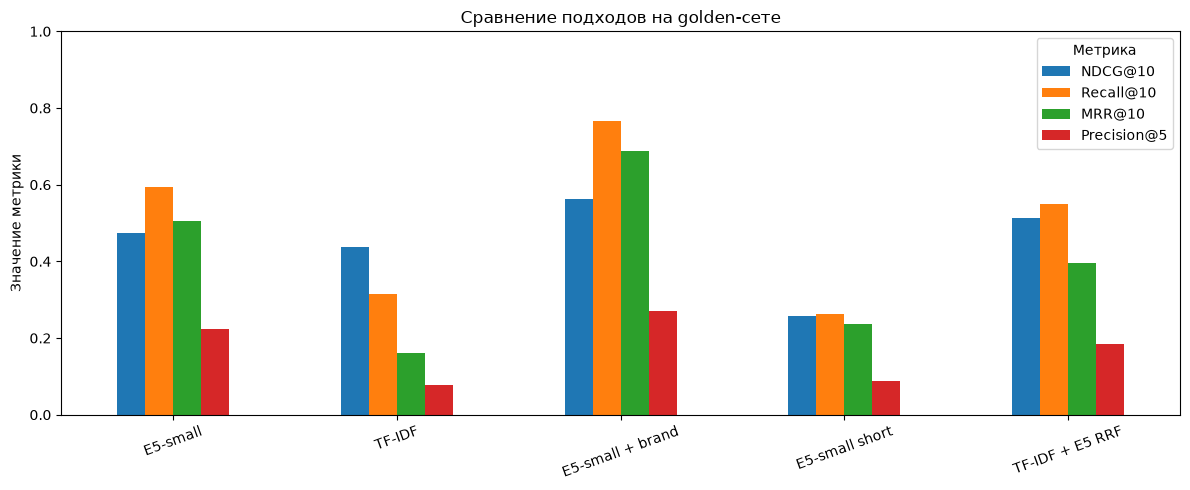

🏃 View run e5_brand at: https://mlflow-ds-20260428-9c124b2073.infra-c2.data-science.education-services.ru/#/experiments/1/runs/4d539145331e43748cdd51671dde67cf
🧪 View experiment at: https://mlflow-ds-20260428-9c124b2073.infra-c2.data-science.education-services.ru/#/experiments/1
График и сводная таблица сохранены в запуске e5_brand


In [120]:
comparison_metrics = ["NDCG@10", "Recall@10", "MRR@10", "Precision@5"]
comparison = all_metrics_summary[comparison_metrics]
ax = comparison.plot.bar(figsize=(12, 5), rot=20)
ax.set_title("Сравнение подходов на golden-сете")
ax.set_xlabel("")
ax.set_ylabel("Значение метрики")
ax.set_ylim(0, 1)
ax.legend(title="Метрика")
plt.tight_layout()
comparison_path = MLFLOW_ARTIFACTS_DIR / "comparison.png"
plt.savefig(comparison_path, dpi=150, bbox_inches="tight")
plt.show()
runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id],
    filter_string="tags.mlflow.runName = 'e5_brand' AND attributes.status = 'FINISHED'",
    order_by=["attributes.start_time DESC"],
    max_results=1
)
assert not runs.empty, "Успешный запуск e5_brand не найден"
with mlflow.start_run(run_id=runs.iloc[0]["run_id"]):
    mlflow.log_artifact(str(comparison_path), artifact_path="comparison")
    mlflow.log_artifact(
        str(MLFLOW_ARTIFACTS_DIR / "metrics_summary.csv"),
        artifact_path="comparison"
    )
print("График и сводная таблица сохранены в запуске e5_brand")

In [121]:
error_query_ids = metrics_by_query_brand.sort_values(
    "NDCG@10", kind="stable"
)["query_id"].head(3)
for query_id in error_query_ids:
    labels = queries_train[queries_train["query_id"].eq(query_id)]
    query = labels["query_text"].iloc[0]
    results = search_semantic_brand(query, top_k=5).merge(
        labels[["item_id", "relevance"]],
        left_on="imt_id",
        right_on="item_id",
        how="left",
        validate="one_to_one"
    ).drop(columns="item_id")
    relevant_products = labels[
        labels["relevance"].ge(RELEVANCE_THRESHOLD)
    ].merge(
        eval_catalog_brand[["imt_id", "imt_name", "brand_name", "product_text"]],
        left_on="item_id",
        right_on="imt_id",
        how="left",
        validate="many_to_one"
    )
    print("Запрос:", query)
    print("Первые пять результатов:")
    display(results)
    print("Релевантные товары по разметке:")
    display(relevant_products[["imt_id", "imt_name", "brand_name", "relevance"]])
    for row in relevant_products.itertuples(index=False):
        print(f"\nimt_id: {row.imt_id}\n{row.product_text}")

Запрос: рубашки с карманами
Первые пять результатов:


,imt_id,imt_name,subj_name,score,relevance
0,10152298,Рубашка,Рубашки,0.871803,NaN
1,10006235,Рубашка,Рубашки,0.868762,NaN
2,10006214,Рубашка,Рубашки,0.866600,NaN
3,10006206,Рубашка,Рубашки,0.866497,NaN
4,10006217,Рубашка,Рубашки,0.866250,NaN


Релевантные товары по разметке:


,imt_id,imt_name,brand_name,relevance
0,1014070,Рубашка,Viaggio bambini,3



imt_id: 1014070
Рубашка
Рубашки
Viaggio bambini
Прекрасная рубашка с отложным воротником и длинными рукавами. Модель с застежкой на пуговицы. На груди изделие дополнено накладным карманом.
Запрос: бежевые футболки
Первые пять результатов:


,imt_id,imt_name,subj_name,score,relevance
0,10050479,Футболка,Футболки,0.886781,NaN
1,10149898,Футболка Для Бега Own The Run,Футболки,0.886473,NaN
2,10050486,Футболка с принтом,Футболки,0.882219,NaN
3,10050485,Футболка с принтом,Футболки,0.882006,NaN
4,10050474,Футболка с принтом,Футболки,0.881583,NaN


... (3 outputs left out)

,imt_id,imt_name,subj_name,score,relevance
0,10057603,Джинсы BIG SIZE Classic,Джинсы,0.899469,NaN
1,10021548,Джинсы,Джинсы,0.895430,NaN
2,10021550,Джинсы,Джинсы,0.894776,NaN
3,10152416,"Джинсы классические, однотонные",Джинсы,0.893700,NaN
4,10016400,Джинсы скинни,Джинсы,0.889511,NaN


Релевантные товары по разметке:


,imt_id,imt_name,brand_name,relevance
0,10035308,Джинсы,ISEE,3



imt_id: 10035308
Джинсы
Джинсы
ISEE
Мы рекомендуем перед выбором сверять Ваши параметры с таблицей размеров, размещённой в фото в карточке товара. Джинсы мужские сшиты из мягкого денима с добавлением полиэфира и эластана, обеспечивающим комфортную посадку изделия по фигуре. Джинсы с легким эффектом "потертости", удобная средняя посадка изделия, шлевки для ремня, зауженный крой брючин, классические "пять карманов", застежка на "молнию" и пуговицу. Джинсовые брюки являются атрибутом повседневной одежды любого мужчины подойдут как домашняя одежда, в офис, для деловой встречи, на вечеринку или свидание в сочетании с мужской футболкой, рубашкой, джемпером, кардиганом, водолазкой торговой марки ISEE. Джинсы подойдут в подарок мужу, папе, любимому на день рождения и 23 февраля. Нас ищут: мужские джинсы летние, брюки мужские летние классические, брюки мужские летние, джинсы мужские прямые, джинсы мужские классические, джинсы мужские больших размеров.


### Разбор запросов с низким NDCG@10
1. **«Рубашки с карманами».** Модель возвращает рубашки, но по названиям нельзя проверить наличие карманов. У размеченного релевантного товара карман явно указан в описании. Возможная причина ошибки — недостаточный учёт конкретного признака; для подтверждения нужно проверить описания найденных товаров.
2. **«Бежевые футболки».** Цвет — важное условие запроса, но отдельное поле цвета не включено в product_text. В описании размеченного товара одновременно упоминаются сиреневый и бежевый варианты, что усложняет поиск на уровне карточки. При дальнейшем развитии стоит проверить использование цвета и фильтрацию по вариантам товара.
3. **«Классические джинсовые джинсы».** В выдаче есть «Джинсы BIG SIZE Classic» и «Джинсы классические, однотонные». По названиям они выглядят подходящими, однако не имеют оценок для этого запроса. Этот пример показывает ограничение неполной разметки: потенциально полезные результаты получают нулевой вклад в метрику.

Во всех трёх случаях требуется дополнительная разметка найденных товаров. Значение NaN означает отсутствие оценки, а не нерелевантность. По этим примерам нельзя однозначно отделить ошибки модели от недостаточного покрытия разметки.

### 4. Финальные выводы

**4.1. Сводная таблица.** Все подходы на одних данных, с одинаковыми порогом и K. Укажите лучшую конфигурацию и метрики, по которым был сделан вывод.

**4.2. Качественный анализ.** Числа показывают не всю картину. Возьмите запросы, где лучший подход всё ещё ошибается, и опишите характер ошибок.

**4.3. Ограничения оценки.** Перечислите ограничения модели и данных, на которых проводились эксперименты. Например:

- разметка синтетическая и пулированная;
- каталог оценки меньше реального;
- запросы сгенерированы, а не собраны от пользователей.

Этот раздел не ослабляет работу, а усиливает её: специалист, понимающий границы своего решения, вызывает больше доверия.

**4.4. Рекомендация бизнесу.** Скажите заказчику, внедрять ли ему векторный поиск или нет, в каком виде его лучше реализовывать, в каких сценариях он будет помогать, а где может ошибаться.

**4.5. Дальнейшие шаги.** Перечислите возможные действия, которые могли бы улучшить результат:

- использовать реальные логи запросов вместо синтетических;
- перейти на ANN-индекс при росте каталога;
- применить фильтры по атрибутам поверх векторного поиска.

Все возможные шаги обоснуйте.


*Ваши выводы:*
### Итоги сравнения
Все конфигурации сравнивались на одинаковых 700 запросах golden-сета и каталоге из 4256 карточек. Порог релевантности — 2, значения K — 1, 3, 5 и 10.

| Подход | NDCG@10 | Recall@10 | MRR@10 | Precision@5 |
|---|---:|---:|---:|---:|
| TF-IDF | 0,4364 | 0,3137 | 0,1618 | 0,0777 |
| E5-small | 0,4741 | 0,5942 | 0,5044 | 0,2246 |
| E5-small + бренд | 0,5633 | 0,7674 | 0,6867 | 0,2711 |
| E5-small без описания | 0,2573 | 0,2635 | 0,2360 | 0,0871 |
| TF-IDF + E5 RRF | 0,5119 | 0,5504 | 0,3950 | 0,1851 |

Лучший результат показал E5-small с добавлением бренда. Этот вариант лидирует по всем рассчитанным метрикам. Удаление описания ухудшило качество. Гибридный поиск повысил NDCG@10 относительно базового E5-small, но снизил остальные метрики.

Выбранную конфигурацию проверил на 300 тестовых запросах: NDCG@10 — 0,5696, Recall@10 — 0,7828, MRR@10 — 0,6477. В 87% запросов в первой десятке есть хотя бы один товар с оценкой не ниже 2.

### Качественный анализ
Разобрал запросы «рубашки с карманами», «бежевые футболки» и «классические джинсовые джинсы». Модель возвращает товары нужной категории, однако названий недостаточно для проверки отдельных признаков. Вся просмотренная выдача этих запросов не имеет оценок, поэтому нельзя однозначно отделить ошибки поиска от неполноты разметки.

### Ограничения
- Запросы синтетические и могут отличаться от реальных запросов покупателей.
- Каталог оценки содержит 4256 карточек, а подготовленный каталог — 48376. Качество на полном каталоге отдельно не подтверждено для лучшей модели.
- Неразмеченные товары считаются нерелевантными, хотя среди них могут быть подходящие.
- Карточка может объединять несколько вариантов товара. Цвет и другие признаки вариантов не всегда однозначно отражены в тексте.
- E5-small ограничен 512 токенами. В базовом шаблоне лимит превышали 1,25% карточек; часть информации могла обрезаться.
- Golden-сет использовался для выбора конфигурации. Независимая итоговая оценка выполнена на test.
- MRR рассчитан с ограничением первой десяткой. В MLflow он также записан как mrr с параметром mrr_cutoff=10.
- Скорость поиска под нагрузкой и влияние на продажи не измерялись.

### Рекомендация бизнесу
Рекомендую пилот векторного поиска на E5-small с брендом, названием, категорией и описанием товара. На подготовленной разметке он превосходит TF-IDF. Это основание для проверки на реальных пользователях, но не для немедленной полной замены поиска.

Особого внимания требуют запросы с точными условиями: цветом, размером, брендом и характеристиками. Семантическая близость сама по себе не гарантирует соблюдения этих условий.

### Дальнейшие шаги
1. Собрать реальные запросы и дополнительно разметить результаты разных моделей, чтобы уменьшить влияние неполной разметки.
2. Проверить фильтры по цвету, размеру и бренду с учётом вариантов товара.
3. Оценить качество и задержку на полном каталоге; при необходимости использовать ANN-индекс.
4. Провести A/B-тест пилота по кликам, добавлениям в корзину и покупкам.